# Proyecto de aula – Corte 3 (versión final)
**Predicción del riesgo de diabetes con clasificación supervisada y segmentación con K-Means (BRFSS 2015)**
Asignatura: Minería de Datos – Universidad de la Costa (CUC)
Integrantes: Jesús Alberto Vargas España, Santiago Patiño Arzayus, Duván Andrés Arzuza Carrascal

**Cambios frente al Corte 2 (documentados):**
1. Todo el flujo se ejecuta en orden y de una sola vez (en el Corte 2 el notebook tenía celdas fuera de orden: duplicados mostrados como 0 tras eliminarlos y una segunda partición sin `stratify`).
2. Preprocesamiento dentro de un `Pipeline` (`ColumnTransformer` + modelo), ajustado solo con entrenamiento: sin fuga de información.
3. Se escalan todas las variables no binarias (antes solo `bmi`).
4. Se agrega línea base (`DummyClassifier`), validación cruzada estratificada de 5 pliegues, comparación entrenamiento vs. prueba y ajuste de hiperparámetros de Gradient Boosting.
5. Se calcula realmente inercia y coeficiente de silueta para K-Means (no se había calculado).
6. El modelo final se guarda como `modelo_diabetes.joblib` y es el mismo que carga la app de Streamlit.

## 1. Configuración y carga de datos

In [1]:
import json, os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import sklearn
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
os.makedirs('figs', exist_ok=True)
RES = {'sklearn': sklearn.__version__}
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


In [2]:
RUTA = 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv'
if not os.path.exists(RUTA):
    from google.colab import files
    files.upload()
df = pd.read_csv(RUTA)
df.columns = df.columns.str.strip().str.lower()
filas0, cols0 = df.shape
nulos = int(df.isna().sum().sum())
duplicados = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
RES['datos'] = dict(filas_iniciales=filas0, columnas=cols0, nulos=nulos, duplicados=duplicados, filas_finales=len(df))
print(RES['datos'])
print(df['diabetes_binary'].value_counts().rename('n').to_frame().assign(pct=lambda t: (t.n/t.n.sum()*100).round(2)))

{'filas_iniciales': 70692, 'columnas': 22, 'nulos': 0, 'duplicados': 1635, 'filas_finales': 69057}
                     n    pct
diabetes_binary              
1.0              35097  50.82
0.0              33960  49.18


## 2. Análisis exploratorio orientado al modelado

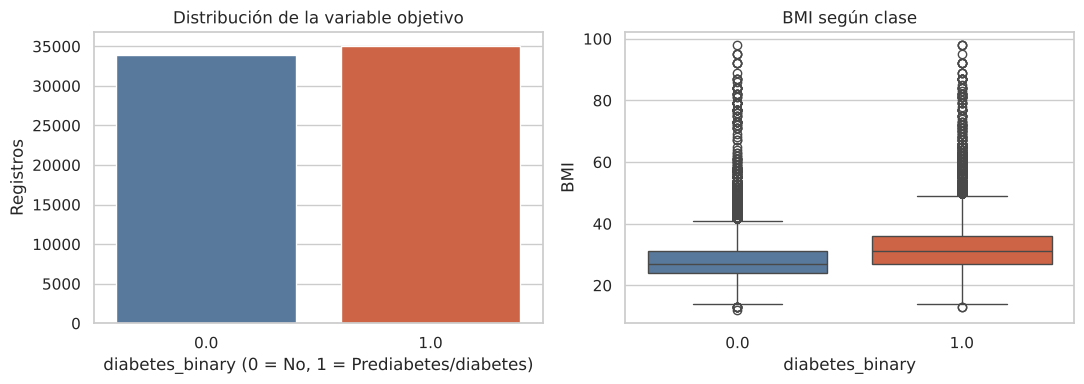

Mediana BMI por clase: {0.0: 27.0, 1.0: 31.0}
Media BMI por clase: {0.0: 27.88, 1.0: 31.96}
BMI atípicos (regla IQR): 2181 | máximo: 98.0


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='diabetes_binary', ax=ax[0], palette=['#4C78A8', '#E4572E'])
ax[0].set(title='Distribución de la variable objetivo', xlabel='diabetes_binary (0 = No, 1 = Prediabetes/diabetes)', ylabel='Registros')
sns.boxplot(data=df, x='diabetes_binary', y='bmi', ax=ax[1], palette=['#4C78A8', '#E4572E'])
ax[1].set(title='BMI según clase', xlabel='diabetes_binary', ylabel='BMI')
plt.tight_layout(); plt.savefig('figs/fig1_objetivo_bmi.png', dpi=160); plt.show()
q1, q3 = df.bmi.quantile([.25, .75]); iqr = q3 - q1
atip = int(((df.bmi < q1-1.5*iqr) | (df.bmi > q3+1.5*iqr)).sum())
print('Mediana BMI por clase:', df.groupby('diabetes_binary').bmi.median().to_dict())
print('Media BMI por clase:', df.groupby('diabetes_binary').bmi.mean().round(2).to_dict())
print('BMI atípicos (regla IQR):', atip, '| máximo:', df.bmi.max())
RES['eda_bmi'] = dict(atipicos=atip, max=float(df.bmi.max()), mediana=df.groupby('diabetes_binary').bmi.median().to_dict())

In [4]:
vars_bin = ['highbp', 'highchol', 'diffwalk', 'heartdiseaseorattack', 'physactivity', 'stroke']
prev = (df.groupby('diabetes_binary')[vars_bin].mean()*100).round(2).T
prev.columns = ['Sin diabetes (%)', 'Con diabetes (%)']
display(prev)
gh = df.assign(grupo=np.where(df.genhlth >= 4, 'genhlth 4-5 (mala/muy mala)', 'genhlth 1-3')).groupby('grupo').diabetes_binary.agg(['mean', 'count'])
gh['mean'] = (gh['mean']*100).round(2); display(gh.rename(columns={'mean': '% con diabetes', 'count': 'n'}))
prev.to_csv('figs/eda_prevalencias.csv'); RES['eda_prev'] = prev.to_dict(); RES['eda_genhlth'] = gh.to_dict()

,Sin diabetes (%),Con diabetes (%)
highbp,38.40,75.23
highchol,38.86,66.95
diffwalk,13.97,37.37
heartdiseaseorattack,7.55,22.38
physactivity,76.67,62.85
stroke,3.32,9.31


,% con diabetes,n
grupo,,
genhlth 1-3,41.51,49958
genhlth 4-5 (mala/muy mala),75.18,19099


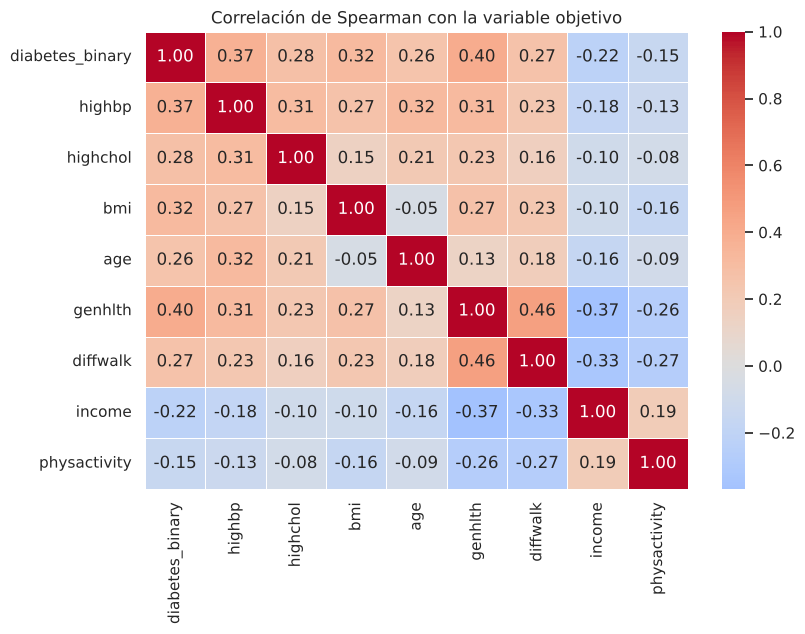

genhlth                 0.403
highbp                  0.372
bmi                     0.319
highchol                0.281
diffwalk                0.267
age                     0.255
heartdiseaseorattack    0.207
physhlth                0.207
stroke                  0.123
cholcheck               0.119
smoker                  0.076
menthlth                0.047
sex                     0.043
nodocbccost             0.036
anyhealthcare           0.027
fruits                 -0.045
veggies                -0.072
hvyalcoholconsump      -0.099
physactivity           -0.150
education              -0.157
income                 -0.219


In [5]:
cols_eda = ['diabetes_binary', 'highbp', 'highchol', 'bmi', 'age', 'genhlth', 'diffwalk', 'income', 'physactivity']
corr = df[cols_eda].corr(method='spearman')
plt.figure(figsize=(8.5, 6.5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Correlación de Spearman con la variable objetivo'); plt.tight_layout(); plt.savefig('figs/fig2_correlacion.png', dpi=160); plt.show()
cor_all = df.corr(method='spearman')['diabetes_binary'].drop('diabetes_binary').sort_values(ascending=False)
print(cor_all.round(3).to_string()); RES['correlaciones'] = cor_all.round(4).to_dict()

## 3. Partición y pipeline (sin fuga de información)
Partición 80/20 estratificada con `random_state=42`. Las variables no binarias (`bmi`, `genhlth`, `menthlth`, `physhlth`, `age`, `education`, `income`) se escalan con `StandardScaler` **dentro del pipeline**, ajustado únicamente con los datos de entrenamiento (y dentro de cada pliegue en la validación cruzada). Las variables binarias pasan sin cambios.

In [6]:
X = df.drop(columns='diabetes_binary'); y = df['diabetes_binary'].astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
NUM = ['bmi', 'genhlth', 'menthlth', 'physhlth', 'age', 'education', 'income']
FEATURES = list(X.columns)
def prep(): return ColumnTransformer([('num', StandardScaler(), NUM)], remainder='passthrough')
def pipe(clf): return Pipeline([('prep', prep()), ('clf', clf)])
print('Entrenamiento:', Xtr.shape, ytr.value_counts().to_dict()); print('Prueba:', Xte.shape, yte.value_counts().to_dict())
RES['split'] = dict(train=len(Xtr), test=len(Xte), train_dist=ytr.value_counts().to_dict(), test_dist=yte.value_counts().to_dict())

Entrenamiento: (55245, 21) {1: 28077, 0: 27168}
Prueba: (13812, 21) {1: 7020, 0: 6792}


## 4. Ajuste de hiperparámetros de Gradient Boosting
Se usa búsqueda en rejilla con validación cruzada (3 pliegues) **solo sobre entrenamiento** y ROC-AUC como criterio (independiente del umbral de decisión).

In [7]:
grid = GridSearchCV(pipe(GradientBoostingClassifier(random_state=SEED)),
                    {'clf__n_estimators': [100, 200], 'clf__max_depth': [3, 5], 'clf__learning_rate': [0.1]},
                    scoring='roc_auc', cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)
grid.fit(Xtr, ytr)
gcv = pd.DataFrame(grid.cv_results_)[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__learning_rate', 'mean_test_score', 'std_test_score']].round(4)
display(gcv); print('Mejor configuración:', grid.best_params_)
print('La rejilla confirma que la configuración por defecto de scikit-learn (100 árboles, profundidad 3, tasa 0.1) es la mejor; no se obtuvo mejora al aumentar árboles o profundidad.')
RES['grid'] = gcv.to_dict('records'); RES['grid_best'] = grid.best_params_
gcv.to_csv('figs/grid_gbm.csv', index=False)

,param_clf__n_estimators,param_clf__max_depth,param_clf__learning_rate,mean_test_score,std_test_score
0,100,3,0.1,0.8256,0.0009
1,200,3,0.1,0.8255,0.0010
2,100,5,0.1,0.8251,0.0009
3,200,5,0.1,0.8232,0.0012


Mejor configuración: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100}
La rejilla confirma que la configuración por defecto de scikit-learn (100 árboles, profundidad 3, tasa 0.1) es la mejor; no se obtuvo mejora al aumentar árboles o profundidad.


## 5. Entrenamiento, validación cruzada y comparación de modelos

In [8]:
bp = grid.best_params_
modelos = {
    'Línea base (clase mayoritaria)': DummyClassifier(strategy='most_frequent'),
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=SEED),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=7, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEED),
    'KNN (k=15)': KNeighborsClassifier(n_neighbors=15),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=bp['clf__n_estimators'], max_depth=bp['clf__max_depth'],
                                                    learning_rate=bp['clf__learning_rate'], random_state=SEED),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, filas_cv, filas_tt = {}, [], []
for nombre, clf in modelos.items():
    p = pipe(clf)
    cv = cross_validate(p, Xtr, ytr, cv=skf, scoring=['accuracy', 'recall', 'f1', 'roc_auc'])
    filas_cv.append({'Modelo': nombre, **{f'CV {m}': cv[f'test_{m}'].mean() for m in ['accuracy', 'recall', 'f1', 'roc_auc']},
                     'CV recall (desv.)': cv['test_recall'].std(), 'CV AUC (desv.)': cv['test_roc_auc'].std()})
    p.fit(Xtr, ytr); fitted[nombre] = p
    fila = {'Modelo': nombre}
    for split, (A, b) in {'train': (Xtr, ytr), 'test': (Xte, yte)}.items():
        pr = p.predict(A); pb = p.predict_proba(A)[:, 1]
        fila.update({f'{split}_accuracy': accuracy_score(b, pr), f'{split}_precision': precision_score(b, pr, zero_division=0),
                     f'{split}_recall': recall_score(b, pr), f'{split}_f1': f1_score(b, pr), f'{split}_auc': roc_auc_score(b, pb)})
    filas_tt.append(fila); print('listo:', nombre)
df_cv = pd.DataFrame(filas_cv).round(4); df_tt = pd.DataFrame(filas_tt).round(4)
display(df_cv); display(df_tt)
df_cv.to_csv('figs/tabla_cv.csv', index=False); df_tt.to_csv('figs/tabla_train_test.csv', index=False)
RES['cv'] = df_cv.to_dict('records'); RES['train_test'] = df_tt.to_dict('records')

listo: Línea base (clase mayoritaria)


listo: Regresión Logística


listo: Árbol de Decisión


listo: Random Forest


listo: KNN (k=15)


listo: Gradient Boosting


,Modelo,CV accuracy,CV recall,CV f1,CV roc_auc,CV recall (desv.),CV AUC (desv.)
0,Línea base (clase mayoritaria),0.5082,1.0000,0.6739,0.5000,0.0000,0.0000
1,Regresión Logística,0.7446,0.7710,0.7542,0.8200,0.0063,0.0036
2,Árbol de Decisión,0.7366,0.7820,0.7511,0.8087,0.0151,0.0040
3,Random Forest,0.7471,0.7968,0.7620,0.8228,0.0075,0.0035
4,KNN (k=15),0.7293,0.7788,0.7451,0.8000,0.0095,0.0042
5,Gradient Boosting,0.7494,0.7953,0.7634,0.8259,0.0056,0.0041


,Modelo,train_accuracy,train_precision,train_recall,train_f1,train_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc
0,Línea base (clase mayoritaria),0.5082,0.5082,1.0000,0.6739,0.5000,0.5083,0.5083,1.0000,0.6740,0.5000
1,Regresión Logística,0.7448,0.7384,0.7710,0.7544,0.8203,0.7449,0.7376,0.7732,0.7550,0.8174
2,Árbol de Decisión,0.7449,0.7306,0.7889,0.7586,0.8195,0.7378,0.7237,0.7829,0.7522,0.8081
3,Random Forest,0.7956,0.7761,0.8402,0.8069,0.8795,0.7468,0.7308,0.7946,0.7613,0.8203
4,KNN (k=15),0.7623,0.7437,0.8123,0.7765,0.8473,0.7318,0.7149,0.7856,0.7486,0.8010
5,Gradient Boosting,0.7523,0.7361,0.7990,0.7663,0.8302,0.7500,0.7331,0.7990,0.7646,0.8237


Modelo final (mayor ROC-AUC en validación cruzada sobre entrenamiento): Gradient Boosting


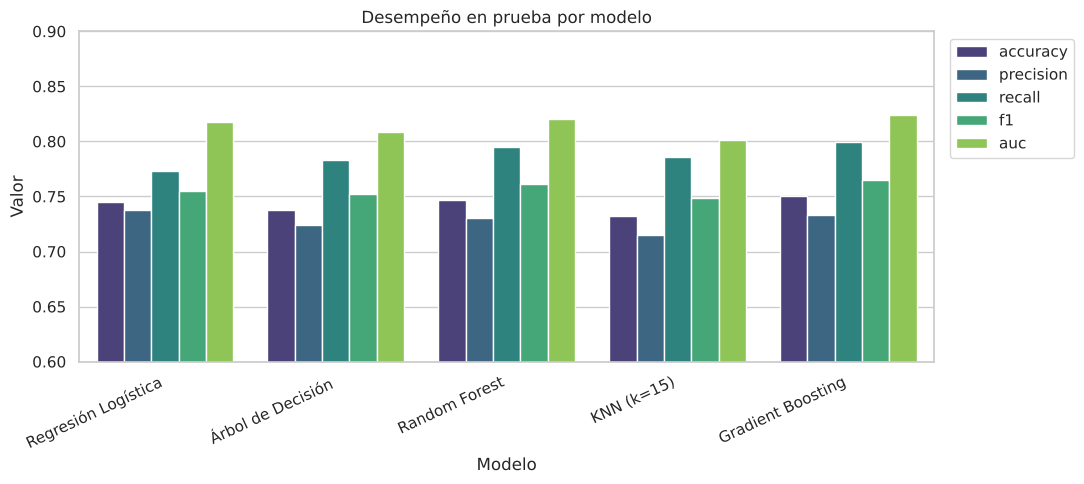

In [9]:
cand = df_cv[~df_cv.Modelo.str.startswith('Línea')].sort_values('CV roc_auc', ascending=False)
FINAL = cand.iloc[0]['Modelo']; final = fitted[FINAL]
print('Modelo final (mayor ROC-AUC en validación cruzada sobre entrenamiento):', FINAL)
RES['modelo_final'] = FINAL
orden = ['Regresión Logística', 'Árbol de Decisión', 'Random Forest', 'KNN (k=15)', 'Gradient Boosting']
t = df_tt.set_index('Modelo').loc[orden]
m = t[['test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_auc']].reset_index().melt('Modelo', var_name='Métrica', value_name='Valor')
m['Métrica'] = m['Métrica'].str.replace('test_', '')
plt.figure(figsize=(11, 5)); sns.barplot(data=m, x='Modelo', y='Valor', hue='Métrica', palette='viridis')
plt.ylim(0.6, 0.9); plt.xticks(rotation=25, ha='right'); plt.title('Desempeño en prueba por modelo'); plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.savefig('figs/fig3_comparacion.png', dpi=160); plt.show()

## 6. Evaluación del modelo final en datos de prueba

                                precision    recall  f1-score   support

        Clase 0 (sin diabetes)       0.77      0.70      0.73      6792
Clase 1 (prediabetes/diabetes)       0.73      0.80      0.76      7020

                      accuracy                           0.75     13812
                     macro avg       0.75      0.75      0.75     13812
                  weighted avg       0.75      0.75      0.75     13812

TN, FP, FN, TP = 4750 2042 1411 5609 | especificidad = 0.6994 | tasa FN = 0.201


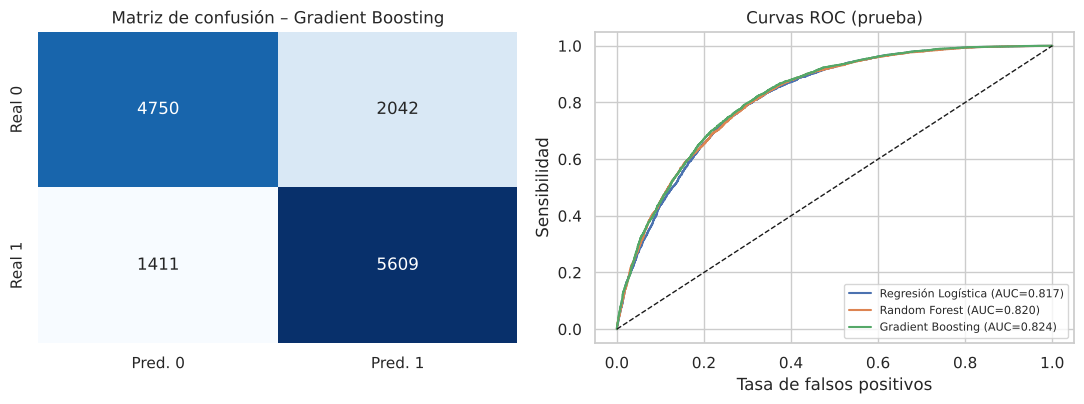

In [10]:
pred = final.predict(Xte); proba = final.predict_proba(Xte)[:, 1]
rep = classification_report(yte, pred, target_names=['Clase 0 (sin diabetes)', 'Clase 1 (prediabetes/diabetes)'], output_dict=True)
print(classification_report(yte, pred, target_names=['Clase 0 (sin diabetes)', 'Clase 1 (prediabetes/diabetes)']))
cm = confusion_matrix(yte, pred); tn, fp, fn, tp = cm.ravel()
print('TN, FP, FN, TP =', tn, fp, fn, tp, '| especificidad =', round(tn/(tn+fp), 4), '| tasa FN =', round(fn/(fn+tp), 4))
RES['reporte'] = rep; RES['cm_final'] = dict(TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0], xticklabels=['Pred. 0', 'Pred. 1'], yticklabels=['Real 0', 'Real 1'])
ax[0].set_title(f'Matriz de confusión – {FINAL}')
for nombre in ['Regresión Logística', 'Random Forest', FINAL]:
    fpr, tpr, _ = roc_curve(yte, fitted[nombre].predict_proba(Xte)[:, 1]); ax[1].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(yte, fitted[nombre].predict_proba(Xte)[:, 1]):.3f})")
ax[1].plot([0, 1], [0, 1], 'k--', lw=1); ax[1].set(title='Curvas ROC (prueba)', xlabel='Tasa de falsos positivos', ylabel='Sensibilidad'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figs/fig4_confusion_roc.png', dpi=160); plt.show()

In [11]:
filas = []
for nombre in orden:
    c = confusion_matrix(yte, fitted[nombre].predict(Xte)).ravel(); filas.append({'Modelo': nombre, 'TN': c[0], 'FP': c[1], 'FN': c[2], 'TP': c[3]})
df_cm = pd.DataFrame(filas); display(df_cm); df_cm.to_csv('figs/tabla_confusion.csv', index=False); RES['cm_todos'] = df_cm.to_dict('records')

,Modelo,TN,FP,FN,TP
0,Regresión Logística,4861,1931,1592,5428
1,Árbol de Decisión,4694,2098,1524,5496
2,Random Forest,4737,2055,1442,5578
3,KNN (k=15),4593,2199,1505,5515
4,Gradient Boosting,4750,2042,1411,5609


In [12]:
filas = []
for thr in [0.50, 0.45, 0.40, 0.35, 0.30]:
    pr = (proba >= thr).astype(int); c = confusion_matrix(yte, pr).ravel()
    filas.append({'Umbral': thr, 'Accuracy': accuracy_score(yte, pr), 'Precision': precision_score(yte, pr), 'Recall': recall_score(yte, pr),
                  'Especificidad': c[0]/(c[0]+c[1]), 'FN': c[2], 'FP': c[1]})
df_thr = pd.DataFrame(filas).round(4); display(df_thr); df_thr.to_csv('figs/tabla_umbral.csv', index=False); RES['umbral'] = df_thr.to_dict('records')

,Umbral,Accuracy,Precision,Recall,Especificidad,FN,FP
0,0.50,0.7500,0.7331,0.7990,0.6994,1411,2042
1,0.45,0.7489,0.7156,0.8396,0.6552,1126,2342
2,0.40,0.7459,0.7003,0.8741,0.6134,884,2626
3,0.35,0.7351,0.6810,0.9007,0.5639,697,2962
4,0.30,0.7236,0.6635,0.9256,0.5149,522,3295


In [13]:
g = Xte.copy(); g['real'] = yte.values; g['pred'] = pred
g['tipo'] = np.select([(g.real == 0) & (g.pred == 0), (g.real == 0) & (g.pred == 1), (g.real == 1) & (g.pred == 0)], ['TN', 'FP', 'FN'], 'TP')
perfil = g.groupby('tipo')[['highbp', 'highchol', 'bmi', 'genhlth', 'age', 'diffwalk', 'physactivity', 'income']].mean().round(2).loc[['TN', 'FP', 'FN', 'TP']]
perfil['n'] = g.tipo.value_counts()
display(perfil); perfil.to_csv('figs/perfil_errores.csv'); RES['perfil_errores'] = perfil.to_dict('index')
fn_hb = g[g.real == 1].groupby('highbp').apply(lambda d: (d.pred == 0).mean()).round(4).to_dict()
fn_ag = g[g.real == 1].assign(edad=lambda d: pd.cut(d.age, [0, 4, 8, 13], labels=['18-44', '45-64', '65+'])).groupby('edad').apply(lambda d: (d.pred == 0).mean()).round(4).to_dict()
print('Tasa de FN entre diabéticos reales según highbp:', fn_hb); print('Tasa de FN por grupo de edad:', fn_ag)
RES['fn_highbp'] = {str(k): v for k, v in fn_hb.items()}; RES['fn_edad'] = {str(k): v for k, v in fn_ag.items()}

,highbp,highchol,bmi,genhlth,age,diffwalk,physactivity,income,n
tipo,,,,,,,,,
TN,0.23,0.28,26.42,2.04,7.07,0.06,0.82,6.53,4750
FP,0.76,0.66,31.17,3.27,9.58,0.34,0.65,5.23,2042
FN,0.38,0.39,27.93,2.41,8.36,0.11,0.77,6.13,1411
TP,0.85,0.74,32.88,3.50,9.64,0.44,0.60,4.99,5609


Tasa de FN entre diabéticos reales según highbp: {0.0: 0.5126, 1.0: 0.101}
Tasa de FN por grupo de edad: {'18-44': 0.6478, '45-64': 0.2767, '65+': 0.1482}


,variable,caída_AUC,desv
13,genhlth,0.0514,0.0019
3,bmi,0.0392,0.0015
18,age,0.0273,0.0015
0,highbp,0.0170,0.0002
1,highchol,0.0117,0.0006
2,cholcheck,0.0042,0.0002
10,hvyalcoholconsump,0.0033,0.0003
6,heartdiseaseorattack,0.0029,0.0004
17,sex,0.0025,0.0003
20,income,0.0025,0.0002


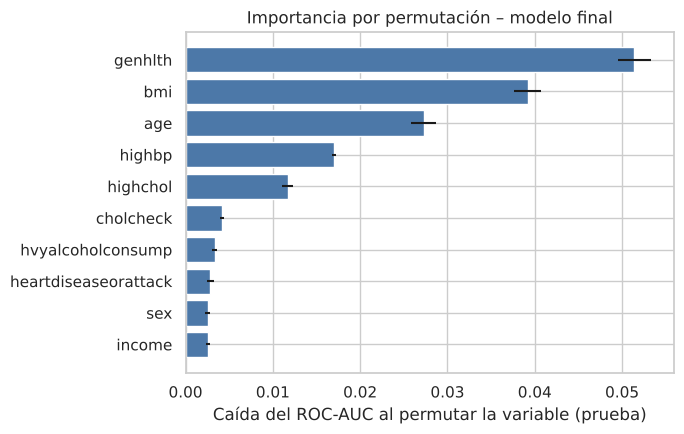

In [14]:
pi = permutation_importance(final, Xte, yte, scoring='roc_auc', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'variable': FEATURES, 'caída_AUC': pi.importances_mean, 'desv': pi.importances_std}).sort_values('caída_AUC', ascending=False)
display(imp.head(10).round(4)); imp.to_csv('figs/importancia.csv', index=False)
plt.figure(figsize=(7, 4.5)); top = imp.head(10).iloc[::-1]; plt.barh(top.variable, top.caída_AUC, xerr=top.desv, color='#4C78A8')
plt.xlabel('Caída del ROC-AUC al permutar la variable (prueba)'); plt.title('Importancia por permutación – modelo final'); plt.tight_layout(); plt.savefig('figs/fig5_importancia.png', dpi=160); plt.show()
RES['importancia'] = imp.head(10).round(5).to_dict('records')

## 7. Agrupamiento con K-Means
Variables: los 21 predictores (sin la etiqueta), estandarizados con `StandardScaler`. La etiqueta `diabetes_binary` se usa **solo después** del agrupamiento para describir los grupos. Los identificadores de clúster no son diagnósticos.

Evidencia de escalamiento (media, desv.) de bmi y income tras estandarizar: 0.0 1.0 0.0 1.0


2 1279928 0.1613


3 1210603 0.0743


4 1145450 0.0818


5 1090633 0.0886


6 1050003 0.0815


7 1005309 0.0936


8 972910 0.0922


,k,Inercia,Silueta
0,2,1.279928e+06,0.1613
1,3,1.210603e+06,0.0743
2,4,1.145450e+06,0.0818
3,5,1.090633e+06,0.0886
4,6,1.050003e+06,0.0815
5,7,1.005309e+06,0.0936
6,8,9.729099e+05,0.0922


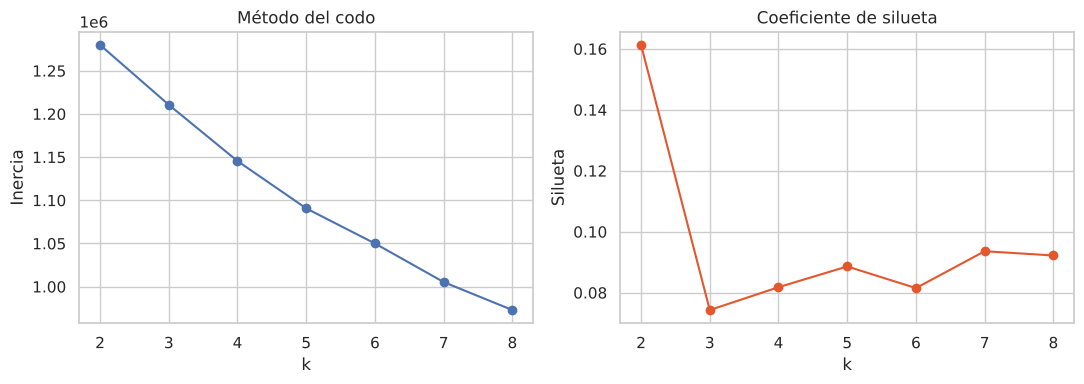

In [15]:
Xs = StandardScaler().fit_transform(X)
print('Evidencia de escalamiento (media, desv.) de bmi y income tras estandarizar:', Xs[:, FEATURES.index('bmi')].mean().round(6), Xs[:, FEATURES.index('bmi')].std().round(4),
      Xs[:, FEATURES.index('income')].mean().round(6), Xs[:, FEATURES.index('income')].std().round(4))
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(Xs)
    sil = silhouette_score(Xs, km.labels_, sample_size=10000, random_state=SEED)
    filas.append({'k': k, 'Inercia': km.inertia_, 'Silueta': sil}); print(k, round(km.inertia_), round(sil, 4))
df_k = pd.DataFrame(filas).round(4); display(df_k); df_k.to_csv('figs/tabla_k.csv', index=False); RES['kmeans_k'] = df_k.to_dict('records')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(df_k.k, df_k.Inercia, 'o-'); ax[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
ax[1].plot(df_k.k, df_k.Silueta, 'o-', color='#E4572E'); ax[1].set(title='Coeficiente de silueta', xlabel='k', ylabel='Silueta')
plt.tight_layout(); plt.savefig('figs/fig6_codo_silueta.png', dpi=160); plt.show()

In [16]:
km2 = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit(Xs)
t2 = X.copy(); t2['diabetes_binary'] = y.values; t2['c'] = km2.labels_
prof2 = t2.groupby('c')[['diabetes_binary', 'highbp', 'bmi', 'genhlth', 'age', 'diffwalk', 'income']].mean().round(3)
prof2.insert(0, 'n', t2.c.value_counts().sort_index()); display(prof2); RES['perfil_k2'] = prof2.to_dict('index')

,n,diabetes_binary,highbp,bmi,genhlth,age,diffwalk,income
c,,,,,,,,
0,45946,0.385,0.452,28.580,2.369,8.173,0.047,6.415
1,23111,0.753,0.808,32.691,3.848,9.462,0.680,4.134


cluster,0,1,2
n,24589.000,28098.000,16370.000
% datos,35.610,40.690,23.710
diabetes_binary,0.203,0.630,0.758
highbp,0.088,0.877,0.773
highchol,0.238,0.691,0.697
bmi,27.398,30.328,33.160
genhlth,2.148,2.787,4.070
age,6.763,9.899,9.146
physactivity,0.842,0.730,0.420
diffwalk,0.034,0.139,0.801


Silueta del k final: 0.0743


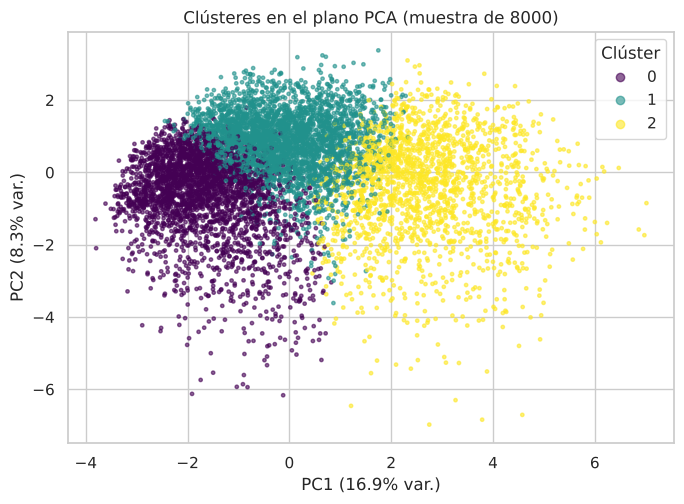

In [17]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit(Xs)
tmp = X.copy(); tmp['diabetes_binary'] = y.values; tmp['raw'] = km.labels_
rank = tmp.groupby('raw').diabetes_binary.mean().sort_values().index.tolist()
tmp['cluster'] = tmp.raw.map({r: i for i, r in enumerate(rank)})
cols_p = ['highbp', 'highchol', 'bmi', 'genhlth', 'age', 'physactivity', 'diffwalk', 'income', 'education', 'menthlth', 'physhlth', 'heartdiseaseorattack']
prof = tmp.groupby('cluster')[['diabetes_binary'] + cols_p].mean().round(3)
prof.insert(0, 'n', tmp.cluster.value_counts().sort_index()); prof.insert(1, '% datos', (prof.n/len(tmp)*100).round(2))
display(prof.T); prof.to_csv('figs/perfil_clusters.csv'); RES['perfil_clusters'] = prof.to_dict('index')
sil_final = silhouette_score(Xs, tmp.raw.values, sample_size=10000, random_state=SEED); print('Silueta del k final:', round(sil_final, 4)); RES['silueta_final'] = float(sil_final)
pca = PCA(2, random_state=SEED); Z = pca.fit_transform(Xs); idx = np.random.RandomState(SEED).choice(len(Z), 8000, replace=False)
plt.figure(figsize=(7, 5.2)); sc = plt.scatter(Z[idx, 0], Z[idx, 1], c=tmp.cluster.values[idx], cmap='viridis', s=6, alpha=.6); plt.legend(*sc.legend_elements(), title='Clúster')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)'); plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)'); plt.title('Clústeres en el plano PCA (muestra de 8000)')
plt.tight_layout(); plt.savefig('figs/fig7_clusters_pca.png', dpi=160); plt.show(); RES['pca_var'] = pca.explained_variance_ratio_.round(4).tolist()

## 8. Persistencia del pipeline final y casos para pruebas de consistencia

In [18]:
joblib.dump(final, 'modelo_diabetes.joblib')
casos = Xte.sample(5, random_state=SEED)
RES['consistencia'] = [{'entrada': {k: float(v) for k, v in r.items()}, 'prediccion': int(final.predict(casos.loc[[i]])[0]),
                        'probabilidad': float(final.predict_proba(casos.loc[[i]])[0, 1])} for i, r in casos.iterrows()]
RES['features'] = FEATURES
json.dump(RES, open('resultados.json', 'w'), ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('Guardado modelo_diabetes.joblib y resultados.json'); print(RES['consistencia'][0])

Guardado modelo_diabetes.joblib y resultados.json
{'entrada': {'highbp': 0.0, 'highchol': 0.0, 'cholcheck': 1.0, 'bmi': 23.0, 'smoker': 0.0, 'stroke': 0.0, 'heartdiseaseorattack': 0.0, 'physactivity': 1.0, 'fruits': 1.0, 'veggies': 1.0, 'hvyalcoholconsump': 0.0, 'anyhealthcare': 1.0, 'nodocbccost': 0.0, 'genhlth': 1.0, 'menthlth': 0.0, 'physhlth': 0.0, 'diffwalk': 0.0, 'sex': 0.0, 'age': 9.0, 'education': 4.0, 'income': 6.0}, 'prediccion': 0, 'probabilidad': 0.05764047826678726}


## 9. Conclusiones
- **EDA:** la presión arterial alta, la autopercepción de salud (`genhlth`), el BMI, la edad y el colesterol alto son las variables más asociadas a la clase positiva; `income` y `physactivity` muestran asociación negativa (asociación, no causalidad).
- **Modelo:** el modelo final se eligió por ROC-AUC en validación cruzada sobre entrenamiento, priorizando además la sensibilidad (recall) por el mayor costo clínico de los falsos negativos. Supera claramente a la línea base.
- **Limitaciones:** datos de encuesta autoinformada (BRFSS 2015, EE. UU.); dataset balanceado artificialmente 50/50 (la prevalencia real es menor), por lo que precision y valores predictivos no son extrapolables; la clase positiva mezcla prediabetes y diabetes; el modelo es una herramienta académica y no sustituye una valoración profesional.
- **K-Means:** los coeficientes de silueta son bajos; los grupos describen patrones, no categorías diagnósticas.

## 10. Declaración y evaluación del uso de inteligencia artificial
Ver la sección correspondiente del artículo final (prompts completos, verificación y evaluación crítica por herramienta: Gemini/ChatGPT en cortes 1 y 2; Claude en el Corte 3).